In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("outputs/deduplicated_papers.csv")

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())

Dataset shape: (339, 12)

Columns: ['query', 'source', 'source_id', 'title', 'authors', 'abstract', 'keywords', 'year', 'doi', 'url', 'doi_normalized', 'title_normalized']


,query,source,source_id,title,authors,abstract,keywords,year,doi,url,doi_normalized,title_normalized
0,machine learning healthcare,PubMed,42876421,Bionic Structural Design of Multifunctional Fl...,"['Mingqian Sheng', 'Mingyang Qiu', 'Enchong Ni...",Rehabilitation medicine is an essential compon...,"['CKD', 'electronic skin', 'machine learning',...",2026.0,10.1002/smtd.71134,https://pubmed.ncbi.nlm.nih.gov/42876421/,10.1002/smtd.71134,bionic structural design of multifunctional fl...
1,machine learning healthcare,PubMed,42876358,Clinical Decision Support Models to Optimize C...,"['Robin Z Y Lu', 'Toni J F Michael', 'Vinayak ...",Controlled ovarian hyperstimulation (COH) is a...,"['clinical decision support', 'controlled ovar...",2026.0,10.1111/cts.70742,https://pubmed.ncbi.nlm.nih.gov/42876358/,10.1111/cts.70742,clinical decision support models to optimize c...
2,machine learning healthcare,PubMed,42876042,Machine learning predictors of post-radiothera...,"['Víctor Aguirre-Bravo', 'Rodrigo El Far', 'Ma...",BACKGROUND: Most evidence on post-radiotherapy...,"['AHA PREVENT score', 'Firth logistic regressi...",2026.0,10.1002/acm2.70862,https://pubmed.ncbi.nlm.nih.gov/42876042/,10.1002/acm2.70862,machine learning predictors of postradiotherap...
3,machine learning healthcare,PubMed,42875776,Mismatch between urban eco-sanitation improvem...,"['Zhen Peng', 'Lin Wang']",BACKGROUND: Health service supply capacity dep...,"['Chinese cities', 'Health service governance'...",2026.0,10.1186/s12913-026-15444-8,https://pubmed.ncbi.nlm.nih.gov/42875776/,10.1186/s12913-026-15444-8,mismatch between urban ecosanitation improveme...
4,machine learning healthcare,PubMed,42875668,Predicting Hospital-associated complications i...,"['Shukhrat Valiev', 'Dilnavoz Yuldasheva', 'Ma...",Machine learning is increasingly used to predi...,"['Data leakage', 'Machine learning', 'Post-sur...",2026.0,10.1007/s40520-026-03507-z,https://pubmed.ncbi.nlm.nih.gov/42875668/,10.1007/s40520-026-03507-z,predicting hospitalassociated complications in...


In [2]:

# Check dataset size
print("Total papers:", len(df))

# Check missing values
print("\nMissing values:")
print(
    df[["title", "abstract", "keywords", "year"]]
    .isna()
    .sum()
)

# Check empty text fields
for col in ["title", "abstract", "keywords"]:
    empty = df[col].fillna("").astype(str).str.strip().eq("")
    print(f"Empty {col}: {empty.sum()}")

# Check source distribution
print("\nPapers by source:")
print(df["source"].value_counts())

# Check duplicate identifiers
print("\nDuplicate non-null DOIs:")
print(df["doi_normalized"].dropna().duplicated().sum())


Total papers: 339

Missing values:
title         1
abstract    111
keywords      0
year         21
dtype: int64
Empty title: 1
Empty abstract: 111
Empty keywords: 0

Papers by source:
source
Crossref    125
PubMed      124
arXiv        90
Name: count, dtype: int64

Duplicate non-null DOIs:
0


In [3]:

# Missing abstracts by source
print("Missing abstracts by source:")

print(
    pd.crosstab(
        df["source"],
        df["abstract"].isna(),
        margins=True
    )
)

# Inspect records without abstracts
print("\nExamples of papers without abstracts:")

display(
    df.loc[
        df["abstract"].isna(),
        ["source", "title", "keywords", "year"]
    ].head(10)
)

# Inspect keyword values
print("\nExamples of keyword values:")

print(df["keywords"].head(10).tolist())

# Check for placeholder strings
print("\nCommon keyword values:")

print(df["keywords"].value_counts().head(10))


Missing abstracts by source:
abstract  False  True  All
source                    
Crossref     17   108  125
PubMed      121     3  124
arXiv        90     0   90
All         228   111  339

Examples of papers without abstracts:


,source,title,keywords,year
5,Crossref,Machine learning for healthcare technologies -...,[],2016.0
6,Crossref,Machine Learning in Healthcare,[],2022.0
7,Crossref,Applied Machine Learning for Healthcare,[],2017.0
8,Crossref,Use of Machine Learning in Healthcare,[],2022.0
9,Crossref,Machine Learning for Healthcare Diagnostics,[],2020.0
16,Crossref,Resiliency of Prairie Agriculture to Climate C...,[],2019.0
17,Crossref,Agriculture,[],NaN
19,Crossref,Climate-Smart Agriculture and International Cl...,[],2016.0
28,Crossref,Chapter 2. Renewable Energy Generation and Sto...,[],2022.0
29,Crossref,Chapter 1. Renewable Energy Storage: Too Many ...,[],2022.0



Examples of keyword values:
["['CKD', 'electronic skin', 'machine learning', 'medical healthcare']", "['clinical decision support', 'controlled ovarian hyperstimulation', 'gonadotropin', 'in vitro fertilization', 'machine learning', 'ovulation trigger', 'precision dosing', 'scoping review']", "['AHA PREVENT score', 'Firth logistic regression', 'Latin America', 'breast cancer radiotherapy', 'cardiac dosimetry', 'cardio‐oncology', 'machine learning', 'post‐radiotherapy cardiotoxicity']", "['Chinese cities', 'Health service governance', 'Health service supply capacity', 'Healthcare resource allocation', 'Interpretable machine learning', 'Urban eco-sanitation environment']", "['Data leakage', 'Machine learning', 'Post-surgical complications', 'Prediction modeling']", '[]', '[]', '[]', '[]', '[]']

Common keyword values:
keywords
[]                             151
['quant-ph']                     4
['cs.RO']                        4
['cs.CY', 'cs.AI']               4
['cs.CR', 'cs.AI', 'cs

In [4]:

# Keep the original dataframe unchanged
bm25_df = df.copy()

# Clean title and abstract fields
for col in ["title", "abstract"]:
    bm25_df[col] = (
        bm25_df[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# Track abstract availability
bm25_df["has_abstract"] = (
    bm25_df["abstract"] != ""
)

# Fix year formatting
bm25_df["year"] = pd.to_numeric(
    bm25_df["year"], errors="coerce"
).astype("Int64")

# Remove records without any searchable text
bm25_df = bm25_df[
    (bm25_df["title"] != "") |
    (bm25_df["abstract"] != "")
].copy()

# Combine title and abstract
bm25_df["bm25_text"] = (
    bm25_df["title"] + " " +
    bm25_df["abstract"]
).str.strip()

# Reset index for stable document positions
bm25_df = bm25_df.reset_index(drop=True)

print("Papers ready for BM25:", len(bm25_df))
print("With abstract:", bm25_df["has_abstract"].sum())
print("Without abstract:", (~bm25_df["has_abstract"]).sum())

display(
    bm25_df[
        ["source", "title", "year",
         "has_abstract", "bm25_text"]
    ].head()
)


Papers ready for BM25: 338
With abstract: 228
Without abstract: 110


,source,title,year,has_abstract,bm25_text
0,PubMed,Bionic Structural Design of Multifunctional Fl...,2026,True,Bionic Structural Design of Multifunctional Fl...
1,PubMed,Clinical Decision Support Models to Optimize C...,2026,True,Clinical Decision Support Models to Optimize C...
2,PubMed,Machine learning predictors of post-radiothera...,2026,True,Machine learning predictors of post-radiothera...
3,PubMed,Mismatch between urban eco-sanitation improvem...,2026,True,Mismatch between urban eco-sanitation improvem...
4,PubMed,Predicting Hospital-associated complications i...,2026,True,Predicting Hospital-associated complications i...


In [5]:

for i, text in enumerate(bm25_df["bm25_text"].head(5), start=1):
    print(f"\n{'='*80}")
    print(f"PAPER {i}")
    print(f"{'='*80}")
    print(text)
    print()



PAPER 1
Bionic Structural Design of Multifunctional Flexible Polypyrrole Sensors for Human Health Monitoring. Rehabilitation medicine is an essential component of universal health coverage, while emerging electronic skin offers new opportunities for portable and personalized healthcare. However, flexible pressure sensors still face trade-offs among sensitivity, detection range, and stability, and gas sensors remain challenged by low-concentration detection and environmental robustness. Herein, a biomimetic "Thalia dealbata" microstructured hydrophobic polypyrrole/polydimethylsiloxane (S@PPy/PDMS) composite sensor was fabricated through a one-step template method and controllable in situ polymerization. The biomimetic PDMS microstructure enhances pressure response, while conductive and NH3-sensitive PPy enables dual-mode pressure and gas sensing on a single flexible platform. The sensor exhibits a wide pressure range of 0-25 kPa, a high sensitivity of 3.617 kPa- 1, and excellent durabi

In [6]:

# Simple word-based tokenisation
import re

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

bm25_df["token_count"] = bm25_df["bm25_text"].apply(
    lambda text: len(tokenize(text))
)

print(bm25_df["token_count"].describe())

print(
    "\nLongest document:",
    bm25_df["token_count"].max(),
    "tokens"
)


count    338.000000
mean     156.710059
std      127.260983
min        1.000000
25%        9.000000
50%      168.500000
75%      251.500000
max      583.000000
Name: token_count, dtype: float64

Longest document: 583 tokens


In [7]:

import re

def tokenize(text):
    return re.findall(r"\b\w+\b", str(text).lower())

# Tokenise all papers
tokenized_corpus = [
    tokenize(text)
    for text in bm25_df["bm25_text"]
]

print("Number of documents:", len(tokenized_corpus))

# Examine tokens from the first paper
print("\nFirst paper tokens:")
print(tokenized_corpus[0][:50])

# Check token counts
bm25_df["token_count"] = [
    len(tokens) for tokens in tokenized_corpus
]

print("\nToken count statistics:")
print(bm25_df["token_count"].describe())


Number of documents: 338

First paper tokens:
['bionic', 'structural', 'design', 'of', 'multifunctional', 'flexible', 'polypyrrole', 'sensors', 'for', 'human', 'health', 'monitoring', 'rehabilitation', 'medicine', 'is', 'an', 'essential', 'component', 'of', 'universal', 'health', 'coverage', 'while', 'emerging', 'electronic', 'skin', 'offers', 'new', 'opportunities', 'for', 'portable', 'and', 'personalized', 'healthcare', 'however', 'flexible', 'pressure', 'sensors', 'still', 'face', 'trade', 'offs', 'among', 'sensitivity', 'detection', 'range', 'and', 'stability', 'and', 'gas']

Token count statistics:
count    338.000000
mean     156.710059
std      127.260983
min        1.000000
25%        9.000000
50%      168.500000
75%      251.500000
max      583.000000
Name: token_count, dtype: float64


In [8]:

%pip install rank-bm25



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:

from rank_bm25 import BM25Okapi

# Build BM25 index using tokenized papers
bm25 = BM25Okapi(tokenized_corpus)

print("BM25 index created successfully")
print("Total indexed documents:", bm25.corpus_size)
print("Average document length:", round(bm25.avgdl, 2))


BM25 index created successfully
Total indexed documents: 338
Average document length: 156.71


In [10]:

query = "climate change agriculture"

# Tokenize query using the same function
tokenized_query = tokenize(query)

# Calculate BM25 scores
scores = bm25.get_scores(tokenized_query)

# Create results dataframe
results = bm25_df.copy()
results["bm25_score"] = scores

# Rank by relevance score
results = results.sort_values(
    "bm25_score",
    ascending=False
)

# Show top 10 results
display(
    results[
        ["title", "source", "year",
         "has_abstract", "bm25_score"]
    ].head(10)
)


,title,source,year,has_abstract,bm25_score
15,Climate Change and Agriculture,Crossref,2023,True,14.463511
19,Climate-Smart Agriculture and International Cl...,Crossref,2016,False,13.201385
16,Resiliency of Prairie Agriculture to Climate C...,Crossref,2019,False,12.625100
278,Intelligent Agricultural Greenhouse Control Sy...,arXiv,2024,True,8.478886
189,Climate change and food security,Crossref,2026,False,7.892834
185,Food Security and Climate Change 101,Crossref,<NA>,False,7.852878
187,Climate Change and Food Security in India,Crossref,2010,False,7.813323
188,Climate Change and Involuntary Migration: Impl...,Crossref,1996,False,7.735398
18,"Climate Change, Agriculture, and Famine",Crossref,2016,True,7.723425
186,Agronomy-Food Security-Climate Change and the ...,Crossref,2020,False,7.697016


In [11]:

# Inspect length and abstract availability
inspection = results[
    [
        "title",
        "source",
        "has_abstract",
        "token_count",
        "bm25_score"
    ]
].head(20)

display(inspection)


,title,source,has_abstract,token_count,bm25_score
15,Climate Change and Agriculture,Crossref,True,106,14.463511
19,Climate-Smart Agriculture and International Cl...,Crossref,False,9,13.201385
16,Resiliency of Prairie Agriculture to Climate C...,Crossref,False,7,12.625100
278,Intelligent Agricultural Greenhouse Control Sy...,arXiv,True,236,8.478886
189,Climate change and food security,Crossref,False,5,7.892834
185,Food Security and Climate Change 101,Crossref,False,6,7.852878
187,Climate Change and Food Security in India,Crossref,False,7,7.813323
188,Climate Change and Involuntary Migration: Impl...,Crossref,False,9,7.735398
18,"Climate Change, Agriculture, and Famine",Crossref,True,133,7.723425
186,Agronomy-Food Security-Climate Change and the ...,Crossref,False,10,7.697016


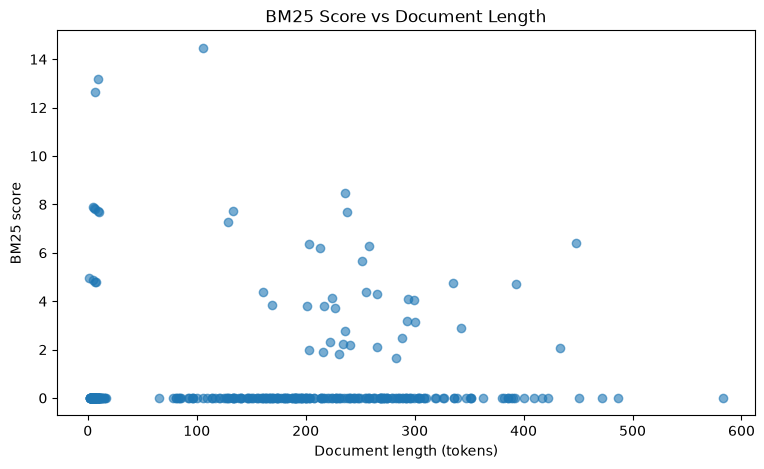

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    results["token_count"],
    results["bm25_score"],
    alpha=0.6
)

plt.xlabel("Document length (tokens)")
plt.ylabel("BM25 score")
plt.title("BM25 Score vs Document Length")

plt.show()


In [13]:

from rank_bm25 import BM25Okapi
import pandas as pd

query = "climate change agriculture"
query_tokens = tokenize(query)

models = {
    "b=0": BM25Okapi(tokenized_corpus, b=0),
    "b=0.75": BM25Okapi(tokenized_corpus, b=0.75),
    "b=1": BM25Okapi(tokenized_corpus, b=1)
}

for name, model in models.items():
    scores = model.get_scores(query_tokens)

    ranked = bm25_df.copy()
    ranked["score"] = scores

    ranked = ranked.sort_values(
        "score", ascending=False
    )

    print(f"\nTop 5 results: {name}")

    display(
        ranked[
            ["title", "token_count",
             "has_abstract", "score"]
        ].head(5)
    )



Top 5 results: b=0


,title,token_count,has_abstract,score
15,Climate Change and Agriculture,106,True,13.609639
278,Intelligent Agricultural Greenhouse Control Sy...,236,True,9.729762
279,Jalisco's multiclass land cover analysis and c...,238,True,9.106600
13,Climate-driven shifts in lumpy skin disease ri...,448,True,8.506872
19,Climate-Smart Agriculture and International Cl...,9,False,8.159284



Top 5 results: b=0.75


,title,token_count,has_abstract,score
15,Climate Change and Agriculture,106,True,14.463511
19,Climate-Smart Agriculture and International Cl...,9,False,13.201385
16,Resiliency of Prairie Agriculture to Climate C...,7,False,12.625100
278,Intelligent Agricultural Greenhouse Control Sy...,236,True,8.478886
189,Climate change and food security,5,False,7.892834



Top 5 results: b=1


,title,token_count,has_abstract,score
16,Resiliency of Prairie Agriculture to Climate C...,7,False,16.864014
19,Climate-Smart Agriculture and International Cl...,9,False,16.780067
15,Climate Change and Agriculture,106,True,14.772632
189,Climate change and food security,5,False,10.627340
185,Food Security and Climate Change 101,6,False,10.531142


In [14]:

from rank_bm25 import BM25Okapi
import pandas as pd
import numpy as np

query = "climate change agriculture"
query_tokens = tokenize(query)

b_values = [0, 0.75, 1]
comparison = bm25_df[
    ["title", "source", "has_abstract", "token_count"]
].copy()

for b in b_values:
    model = BM25Okapi(
        tokenized_corpus,
        k1=1.5,
        b=b
    )

    scores = model.get_scores(query_tokens)

    comparison[f"score_b{b}"] = scores
    comparison[f"rank_b{b}"] = (
        pd.Series(scores, index=comparison.index)
        .rank(ascending=False, method="min")
        .astype(int)
    )

display(
    comparison.sort_values("rank_b0.75").head(10)
)


,title,source,has_abstract,token_count,score_b0,rank_b0,score_b0.75,rank_b0.75,score_b1,rank_b1
15,Climate Change and Agriculture,Crossref,True,106,13.609639,1,14.463511,1,14.772632,3
19,Climate-Smart Agriculture and International Cl...,Crossref,False,9,8.159284,5,13.201385,2,16.780067,2
16,Resiliency of Prairie Agriculture to Climate C...,Crossref,False,7,7.197580,6,12.625100,3,16.864014,1
278,Intelligent Agricultural Greenhouse Control Sy...,arXiv,True,236,9.729762,2,8.478886,4,8.140859,9
189,Climate change and food security,Crossref,False,5,4.454382,20,7.892834,5,10.627340,4
185,Food Security and Climate Change 101,Crossref,False,6,4.454382,20,7.852878,6,10.531142,5
187,Climate Change and Food Security in India,Crossref,False,7,4.454382,20,7.813323,7,10.436670,6
188,Climate Change and Involuntary Migration: Impl...,Crossref,False,9,4.454382,20,7.735398,8,10.252721,7
18,"Climate Change, Agriculture, and Famine",Crossref,True,133,7.197580,6,7.723425,9,7.916208,10
186,Agronomy-Food Security-Climate Change and the ...,Crossref,False,10,4.454382,20,7.697016,10,10.163156,8


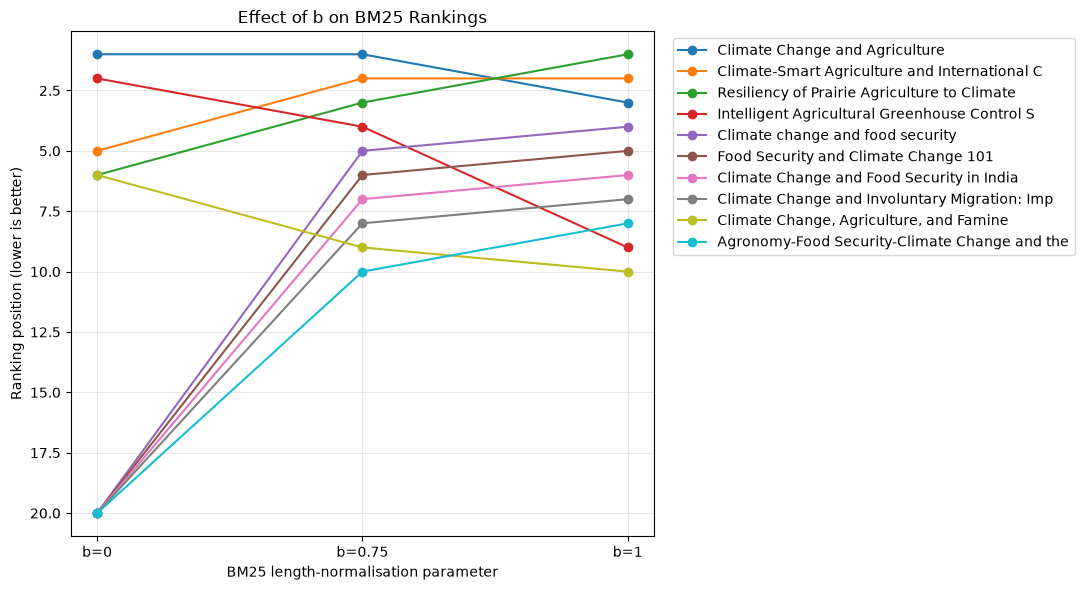

In [15]:

import matplotlib.pyplot as plt

top10 = comparison.sort_values("rank_b0.75").head(10)

fig, ax = plt.subplots(figsize=(11, 6))

for _, paper in top10.iterrows():
    ranks = [
        paper["rank_b0"],
        paper["rank_b0.75"],
        paper["rank_b1"]
    ]

    ax.plot(
        ["b=0", "b=0.75", "b=1"],
        ranks,
        marker="o",
        label=paper["title"][:45]
    )

ax.invert_yaxis()
ax.set_ylabel("Ranking position (lower is better)")
ax.set_xlabel("BM25 length-normalisation parameter")
ax.set_title("Effect of b on BM25 Rankings")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [16]:

summary = []

for b in b_values:
    top = comparison.nsmallest(
        10, f"rank_b{b}"
    )

    summary.append({
        "b": b,
        "Mean tokens (Top 10)": round(
            top["token_count"].mean(), 1
        ),
        "Missing abstracts (Top 10)": (
            (~top["has_abstract"]).sum()
        ),
        "Mean BM25 score (Top 10)": round(
            top[f"score_b{b}"].mean(), 2
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


,b,Mean tokens (Top 10),Missing abstracts (Top 10),Mean BM25 score (Top 10)
0,0.00,184.5,2,8.51
1,0.75,52.8,7,9.55
2,1.00,52.8,7,11.65


In [17]:

test_queries = [
    "climate change agriculture",
    "machine learning healthcare",
    "renewable energy storage",
    "quantum computing",
    "artificial intelligence robotics"
]

def search_bm25(query, top_k=10):
    query_tokens = tokenize(query)
    scores = bm25.get_scores(query_tokens)

    ranked_indices = np.argsort(scores)[::-1][:top_k]

    retrieved = bm25_df.iloc[ranked_indices].copy()
    retrieved["bm25_score"] = scores[ranked_indices]

    return retrieved[
        ["title", "source", "year",
         "has_abstract", "bm25_score"]
    ]

for query in test_queries:
    print(f"\nQUERY: {query}")
    display(search_bm25(query, top_k=5))



QUERY: climate change agriculture


,title,source,year,has_abstract,bm25_score
15,Climate Change and Agriculture,Crossref,2023,True,14.463511
19,Climate-Smart Agriculture and International Cl...,Crossref,2016,False,13.201385
16,Resiliency of Prairie Agriculture to Climate C...,Crossref,2019,False,12.625100
278,Intelligent Agricultural Greenhouse Control Sy...,arXiv,2024,True,8.478886
189,Climate change and food security,Crossref,2026,False,7.892834



QUERY: machine learning healthcare


,title,source,year,has_abstract,bm25_score
6,Machine Learning in Healthcare,Crossref,2022,False,10.951282
7,Applied Machine Learning for Healthcare,Crossref,2017,False,10.895560
9,Machine Learning for Healthcare Diagnostics,Crossref,2020,False,10.895560
8,Use of Machine Learning in Healthcare,Crossref,2022,False,10.840402
5,Machine learning for healthcare technologies -...,Crossref,2016,False,10.785800



QUERY: renewable energy storage


,title,source,year,has_abstract,bm25_score
25,Optimal sizing of renewable energy storage: A ...,arXiv,2022,True,15.126207
31,Renewable Energy Technologies and Energy Stora...,Crossref,2026,False,14.285079
32,Renewable-storage sizing approaches for centra...,Crossref,2024,False,14.030495
30,Storage of Renewable Energy,Crossref,2024,False,13.871618
28,Chapter 2. Renewable Energy Generation and Sto...,Crossref,2022,False,13.662008



QUERY: quantum computing


,title,source,year,has_abstract,bm25_score
283,A Gentle Introduction to Quantum Computing Alg...,arXiv,2020,True,11.489794
284,The Universality of the Quantum Fourier Transf...,arXiv,2000,True,11.066674
38,Emerging quantum computing algorithms for quan...,arXiv,2021,True,10.682396
286,A Quantum-compute Algorithm for Exact Laser-dr...,arXiv,2022,True,9.685681
285,A polynomial quantum computing algorithm for s...,arXiv,2023,True,9.198840



QUERY: artificial intelligence robotics


,title,source,year,has_abstract,bm25_score
93,Robotics and HSI in Robotics,Crossref,2020,False,8.513220
95,6 Robotics and HSI in Robotics,Crossref,2021,False,8.487946
50,Artificial Intelligence and Human Society (Art...,Crossref,2023,True,8.062288
53,ARTIFICIAL INTELLIGENCE AND EDUCATION,Crossref,2020,False,7.643461
54,Third international conference on artificial i...,Crossref,1987,False,7.490235


In [18]:

# Combine the top 5 results for all test queries
all_results = []

for query in test_queries:
    retrieved = search_bm25(query, top_k=5).copy()
    retrieved.insert(0, "search_query", query)
    retrieved.insert(1, "rank", range(1, len(retrieved) + 1))
    all_results.append(retrieved)

# Create a single comparison table
combined_results = pd.concat(
    all_results, ignore_index=True
)

display(combined_results)

# Export to CSV
combined_results.to_csv(
    "outputs/bm25_multiquery_results.csv",
    index=False
)

print("Results saved successfully!")


,search_query,rank,title,source,year,has_abstract,bm25_score
0,climate change agriculture,1,Climate Change and Agriculture,Crossref,2023,True,14.463511
1,climate change agriculture,2,Climate-Smart Agriculture and International Cl...,Crossref,2016,False,13.201385
2,climate change agriculture,3,Resiliency of Prairie Agriculture to Climate C...,Crossref,2019,False,12.625100
3,climate change agriculture,4,Intelligent Agricultural Greenhouse Control Sy...,arXiv,2024,True,8.478886
4,climate change agriculture,5,Climate change and food security,Crossref,2026,False,7.892834
5,machine learning healthcare,1,Machine Learning in Healthcare,Crossref,2022,False,10.951282
6,machine learning healthcare,2,Applied Machine Learning for Healthcare,Crossref,2017,False,10.895560
7,machine learning healthcare,3,Machine Learning for Healthcare Diagnostics,Crossref,2020,False,10.895560
8,machine learning healthcare,4,Use of Machine Learning in Healthcare,Crossref,2022,False,10.840402
9,machine learning healthcare,5,Machine learning for healthcare technologies -...,Crossref,2016,False,10.785800


Results saved successfully!


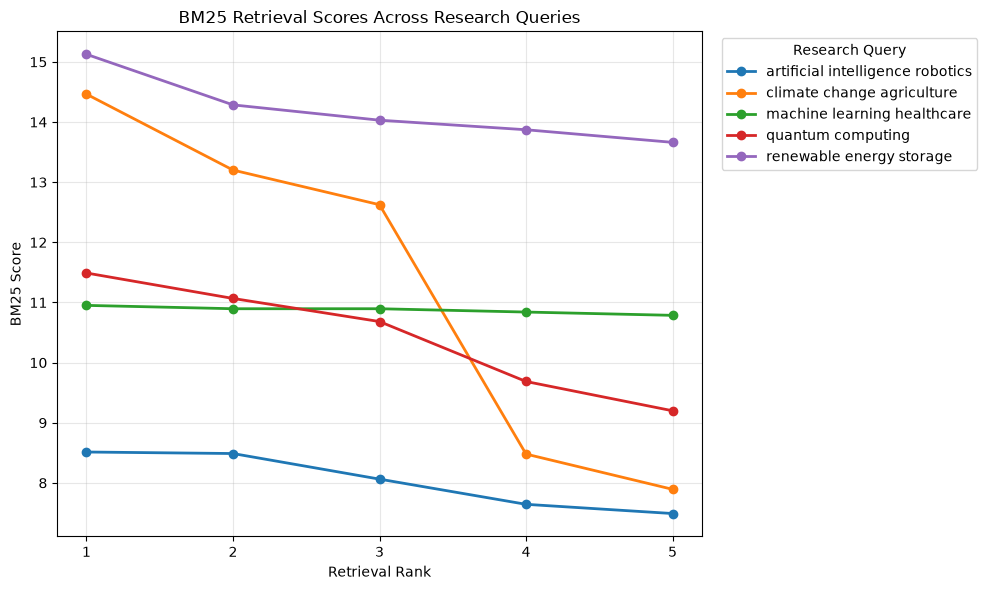

In [19]:

import matplotlib.pyplot as plt
import pandas as pd

# Use the combined results from our previous step
plot_df = combined_results.copy()

plt.figure(figsize=(10, 6))

for query, group in plot_df.groupby("search_query"):
    group = group.sort_values("rank")

    plt.plot(
        group["rank"],
        group["bm25_score"],
        marker="o",
        linewidth=2,
        label=query
    )

plt.xlabel("Retrieval Rank")
plt.ylabel("BM25 Score")
plt.title("BM25 Retrieval Scores Across Research Queries")

plt.xticks([1, 2, 3, 4, 5])
plt.legend(title="Research Query", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
